# Ponts et géométrie d'une molécule

Donner un SMILES, puis exécuter tout le notebook : têtes de pont (RDKit) sur le dessin 2D, puis structure 3D
(conformères ETKDGv3 optimisés au champ de force MMFF94, celle d'énergie minimale) avec en violet les atomes lourds à
plus de `SEUIL` Å du plan moyen.

In [171]:
SMILES = "C1=CC2=CC5=CC=C(C=C4C=CC(C=C3C=CC(=CC1=N2)N3)=N4)N5"  

In [172]:
import numpy as np
import py3Dmol
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import AllChem, Draw, rdMolDescriptors

mol = Chem.MolFromSmiles(SMILES)


# --- code fourni, repris tel quel ---
def i_overlap(mol: Chem.Mol) -> float:
    """Mean excess ring memberships per heavy atom."""
    n_heavy = mol.GetNumHeavyAtoms()
    if n_heavy == 0:
        return 0.0

    ring_info = mol.GetRingInfo()
    memberships = (
        ring_info.NumAtomRings(atom.GetIdx())
        for atom in mol.GetAtoms()
        if atom.GetAtomicNum() > 1
    )
    return sum(max(n_rings - 1, 0) for n_rings in memberships) / n_heavy


def num_bridgehead_atoms(mol: Chem.Mol) -> int:
    """RDKit bridgehead atoms: rings sharing at least two bonds."""
    return rdMolDescriptors.CalcNumBridgeheadAtoms(mol)


def num_spiro_atoms(mol: Chem.Mol) -> int:
    """RDKit spiro atoms: rings sharing exactly one atom."""
    return rdMolDescriptors.CalcNumSpiroAtoms(mol)


def bridgehead_plus_spiro(mol: Chem.Mol) -> int:
    return num_bridgehead_atoms(mol) + num_spiro_atoms(mol)
# --- fin du code fourni ---

## Ponts

têtes de pont : 8  atomes [2, 4, 7, 9, 12, 14, 17, 19]
atomes spiro : 0 ; bridgehead + spiro : 8
i_overlap : 0.50


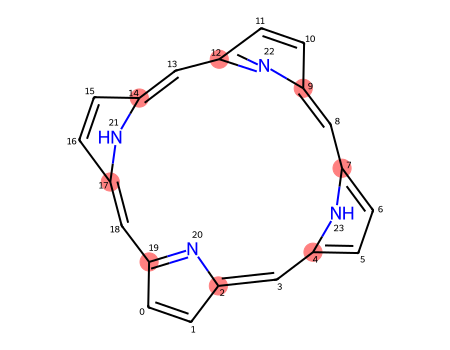

en couleur : têtes de pont


In [173]:
tetes = []
rdMolDescriptors.CalcNumBridgeheadAtoms(mol, atoms=tetes)  # RDKit remplit la liste des têtes de pont
print(f"têtes de pont : {num_bridgehead_atoms(mol)}  atomes {sorted(tetes)}")
print(f"atomes spiro : {num_spiro_atoms(mol)} ; bridgehead + spiro : {bridgehead_plus_spiro(mol)}")
print(f"i_overlap : {i_overlap(mol):.2f}")

dessin = Chem.Mol(mol)
for atome in dessin.GetAtoms():
    atome.SetProp("atomNote", str(atome.GetIdx()))
display(Draw.MolToImage(dessin, size=(450, 350), highlightAtoms=sorted(tetes)))
print("en couleur : têtes de pont")

## Molécule en 3D

In [174]:
CONFORMERES, SEUIL = 20, 0.25  # SEUIL : écart au plan moyen (Å) au-delà duquel un atome est colorié

avec_h = Chem.AddHs(mol)
params = AllChem.ETKDGv3()
params.randomSeed = 0
ids = list(AllChem.EmbedMultipleConfs(avec_h, CONFORMERES, params))
if not ids:
    raise RuntimeError("plongement 3D impossible")
energies = [e for _, e in AllChem.MMFFOptimizeMoleculeConfs(avec_h, maxIters=2000)]
conf = ids[int(np.argmin(energies))]
pos = avec_h.GetConformer(conf).GetPositions()

lourds = [a.GetIdx() for a in avec_h.GetAtoms() if a.GetAtomicNum() > 1]
centre = pos[lourds].mean(axis=0)
normale = np.linalg.svd(pos[lourds] - centre)[2][-1]
distances = np.abs((pos[lourds] - centre) @ normale)
hors = [(i, d) for i, d in zip(lourds, distances) if d > SEUIL]
print(f"écart au plan moyen des atomes lourds : RMS {np.sqrt(np.mean(distances ** 2)):.2f} Å, "
      f"max {distances.max():.2f} Å ; {len(hors)} atomes à plus de {SEUIL} Å")

vue = py3Dmol.view(width=650, height=450)
vue.addModel(Chem.MolToMolBlock(avec_h, confId=conf), "mol")
vue.setStyle({"stick": {"radius": 0.15}, "sphere": {"scale": 0.22}})
vue.zoomTo()
vue.show()

écart au plan moyen des atomes lourds : RMS 0.00 Å, max 0.00 Å ; 0 atomes à plus de 0.25 Å


3Dmol.js failed to load for some reason. Please check your browser console for error messages.